# Smoothing implementation
Following Curve and surface smoothing without shrinkage - Computer Vision, 1995.

## Imports

I created a monkey in Blender and exported as a wavefront object (obj).  We import the mesh using a library called `trimesh`.

In [11]:
# Uncomment the following line to install required libraries
# !pip install trimesh plotly numpy

In [12]:
import numpy as np
import trimesh

# load the object: 
# force="mesh" to load the object as a single mesh
# process=False so that trimesh doesn't clean up the object we loaded; we need the original version
mesh = trimesh.load("monkey.obj", force="mesh", process=False)

# let's look at the mesh
mesh 

<trimesh.Trimesh(vertices.shape=(507, 3), faces.shape=(967, 3))>

`mesh` returns a Trimesh object with two parameters: vertices and faces. Both are _ $\times$ 3-dimensional matrices since our object is 3D.

How do we get the edges?

In [13]:
V, F = np.array(mesh.vertices), np.array(mesh.faces)
# let's take a look at these arrays
print("vertices:\n", V[:5]) # the first 5 vertices
print("\nfaces:\n", F[:5]) # the first 5 faces

vertices:
 [[ 0.4375    0.164062  0.765625]
 [-0.4375    0.164062  0.765625]
 [ 0.5       0.09375   0.6875  ]
 [-0.5       0.09375   0.6875  ]
 [ 0.546875  0.054688  0.578125]]

faces:
 [[46  2 44]
 [ 3 47 45]
 [44  4 42]
 [ 5 45 43]
 [ 2  6  4]]


An interesting point here: V returns the coordinates of each vertex. Since all of our faces are triangles (we chose triangulated meshes when exporting from Blender) and triangles contain 3 vertices each, F returns the indices of those vertices. Hence, \[46, 2, 44\] would be a triangle, the first vertex of which is the vertex number 46 in the array, the second vertex is 2, and the last one is 44.

In [14]:
import plotly.graph_objects as go

def show(V, F, color='lightgray'):
    fig = go.Figure(go.Mesh3d(
        x=V[:, 0], y=V[:, 1], z=V[:, 2],
        i=F[:, 0], j=F[:, 1], k=F[:, 2],
        color=color,
        flatshading=True, # shades each triangle separately
    ))
    fig.update_layout(scene=dict(aspectmode="data")) # keeps the axes at equal scale
    fig.show()

show(V, F)

Pretty cool, but it's rotated. That's because Blender uses Z as the up-axis, while OBJ uses Y. Optionally, we can rotate it back to normal coordinates. To do this, remember basic linear algebra and transformation matrices. The $x$ coordinate stays in place, $y$ becomes $z$, and $z$ becomes $-y$.

$$\begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} \Rightarrow \begin{bmatrix} 1 & 0 & 0 \\ 0 & 0 & -1 \\ 0 & 1 & 0 \end{bmatrix}.$$

Now, if we multiply this rotation matrix by our vector $[x, y, z]$, we get


$$\begin{bmatrix} 1 & 0 & 0 \\ 0 & 0 & -1 \\ 0 & 1 & 0 \end{bmatrix} \times \begin{bmatrix} x \\ y \\ z \end{bmatrix} = \begin{bmatrix} x \\ -z \\ y \end{bmatrix}.$$

A clearer visualization is given below:

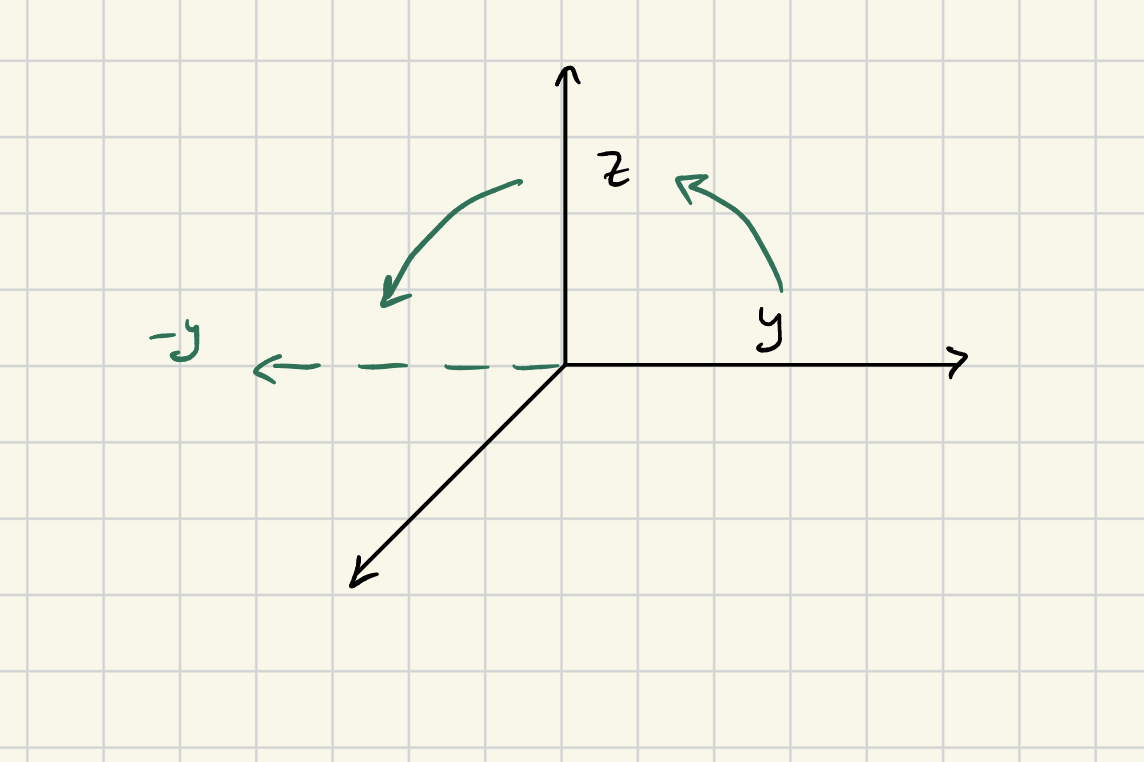

In [15]:
# in code:
V = np.column_stack([V[:, 0], -V[:, 2], V[:, 1]])
# let's try plotting again:
show(V, F)

## Terminology

Next, let's clarify some of the terminology:

- First-order neighborhood of a vertex $v_i$: a set $i^*$ of indices that is directly connected to $v_i$ via an edge.
- Gaussian smoothing: an algorithm that replaces the position of each vertex following this formula: $$v_i' = v_i + \lambda \Delta v_i,$$ where $v_i'$ is the new vertex position, $\lambda$ is a positive scale factor such that $0 < \lambda < 1$, and $$\Delta v_i = \sum_{j \in i^*} w_{ij}(v_j-v_i) = \sum_{j \in i^*} w_{ij}v_j - \sum_{j \in i^*} w_{ij}v_i$$ is a vector average with $w_{ij}$ being the positive weights that add up to 1. Gaussian smoothing must be applied iteratively in order to achieve significant smoothing, but it has a problem of shrinkage, which means that the original object loses its volume and shrinks.

Let's simplify that expression. As we already mentioned, $\sum_j{w_{ij}} = 1$. Since the second term depends only on $i$, we get the original matrix $\sum_{j \in i^*} w_{ij}v_i = v_i$. The first term gives us the weight matrix applied to all vertices in the neighborhood (not necessarily a first-order neighborhood. In other words, $W \times V$, with $W$ being the operator that gives us the weights, and $V$ being the original matrix of vertex positions.

Now how do we compute $W$? We can factorize it as $$W = DE,$$ where $W$ is a full $n\times n$ matrix of weights; $D$ is a diagonal matrix with the number of neighbors along the main diagonal; and $E$ is a symmetric matrix with entries of 1 if the vertices are direct neighbors and 0 otherwise. For simplicity, the weight $w_{ij}$ will be the inverse of the number of neighbors. All neighbors weigh the same.

In the following cell, we implement Gaussian smoothing. First, we create a copy of the vertices of the original mesh so that we don't mess them.

## Gaussian smoothing

In [16]:
V_gs, F_gs = V.copy(), F.copy()
def gaussian_smoothing(V, F, lam=0.3):
    
    # construct E:
    n = len(V)
    E = np.zeros(shape=(n, n)) # n x n symmetric matrix of neighbors
    # a trick to map all the neighbors: 
    rows = np.concatenate([F[:, 0], F[:, 1], F[:, 2]])
    cols = np.concatenate([F[:, 1], F[:, 2], F[:, 0]])
    # let (i, j, k) be the indices of triangle's three vertices
    # this way, set all [i][j], [j][k], and [k][i] entries to 1
    E[rows, cols] = 1
    # since the matrix is symmetric, we apply the same procedure to the transpose
    E[cols, rows] = 1

    # construct D:
    D = np.diag(1 / np.sum(E, axis=1)) # a diagonal matrix, where each diagonal entry = 1 / the number of neighbors
    # axis doesn't matter since the matrix is symmetric

    # construct W, the weight matrix
    W = D @ E
    Delta_V = W @ V - V

    new_V = V + lam * Delta_V
    
    return new_V, W

In [17]:
# let's see what the weight matrix looks like
V_1, W = gaussian_smoothing(V_gs, F_gs)
print(W) # a very cool symmetric matrix

[[0.         0.         0.16666667 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.16666667 0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.         0.         0.14285714]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.14285714 0.         0.        ]]


In [18]:
# verify that all columns are normalized:
print(np.sum(W, axis=1))

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.

In [19]:
# Next up, visualize the new monkey after one step of Gaussian smoothing
show(V_1, F_gs)

You can't really see the difference, but let's repeat Gaussian smoothing for 5, 20, and 50 steps:

In [20]:
for i in range(51):
    V_1, W = gaussian_smoothing(V_1, F_gs)
    if i in [5, 20, 50]:
        show(V_1, F_gs)

The monkey is becoming uglier, unfortunately. That's the problem with Gaussian smoothing. Next, we implement the new method that allows us smoothe a mesh without losing the volume.